# PYTORCH


Strojno učenje je spreminjanje podtakov v števike, in iskanje vzorcev v teh številkah.

Globoko učenje se uporablja, ko govorimo o nestrukturiranih podatkih.



In [68]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print(torch.__version__)
from torch import nn



2.14.1+cu130


## Tensor

- osnovna oblika torcha je tensor (neke vrste multi dimenziniran array)

- Ima lahko n-število dimenzij:

    - skalar (številka): 0 dimenzij
    - vektor [1, 2, 3]: 1 dimenzija
    - matrika (višina, širina): 2 dimenziji
    - 3D tensor (npr. barvna slika (višina, širina, globina)): 3 dimenzije 
    - ...

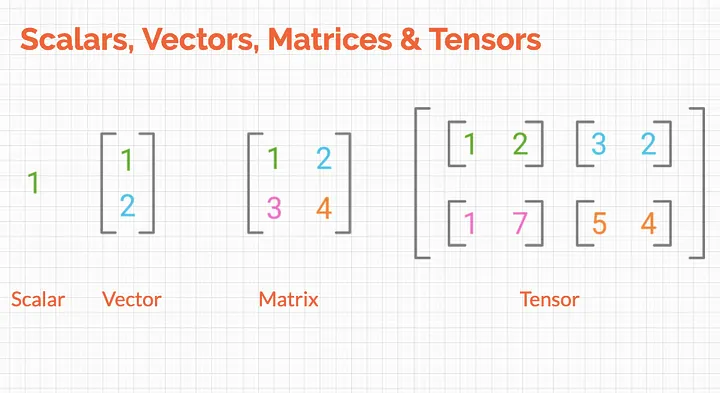


Naredi se ga lahko:

- iz podatkov z `torch.tensor(podatki)`

- iz poljubne oblike `torch.ones/zeros/randn(oblika)`

- oponašanje že obstoječega tensorja `torch.rand_like(podatki, dtype=torch.float)`


Trije atributi tensorja so:

- oblika (vrstice in stolpci)
- podatkovni tip (najpogosteje **float32**, ker je se da minimalno spreminjati vrednosti, za razlike od int)
- naprava (cpu/gpu)


In [69]:
podatki =[[1,2,3],
          [4,5,6]]

moj_tensor=torch.tensor(podatki, dtype=torch.float32)

print(moj_tensor)

oblika=(2,3)

random=torch.randn(oblika)

print(random)
print()

rand_kot_podatki= torch.rand_like(moj_tensor,dtype=torch.float) 

print(rand_kot_podatki) #oblika ista kot moj_tensor, vendar je vsebina drugačna


tensor([[1., 2., 3.],
        [4., 5., 6.]])
tensor([[ 1.2176, -0.8914,  0.7860],
        [ 1.0060,  0.8448, -0.1627]])

tensor([[0.7581, 0.9037, 0.9555],
        [0.1035, 0.6258, 0.2849]])


In [70]:
print(f"\nTensor je dimenzije {moj_tensor.ndim}\n") # z ndim lahko hitro preverimo dimenzije 
print(f"Oblika: {moj_tensor.shape}")
print()
print(f"Podatkovni tip: {moj_tensor.dtype}")
print()
print(f"Device: {moj_tensor.device}")


Tensor je dimenzije 2

Oblika: torch.Size([2, 3])

Podatkovni tip: torch.float32

Device: cpu


### 3D tensor

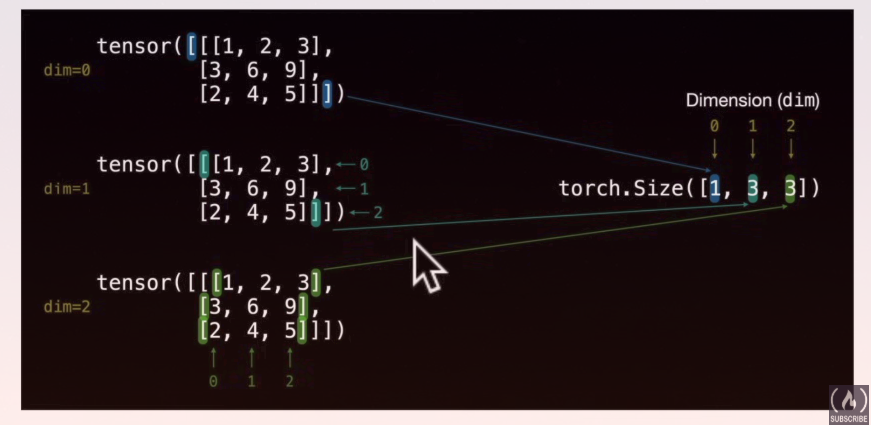

In [71]:
# 3D tensor

tri_D_tensor=torch.tensor([[[1, 2, 3],
                      [4, 5, 6],
                      [8, 9, 10]]])

print(tri_D_tensor.shape)

tri_D_tensor.ndim

torch.Size([1, 3, 3])


3

### `torch.arange`

Za delanje tensorje z dosegom.

In [72]:
torch.arange(start=1, end=999, step=65)

tensor([  1,  66, 131, 196, 261, 326, 391, 456, 521, 586, 651, 716, 781, 846,
        911, 976])

### Pogosti errorji

Trije najpogostrjši errorji so: 

- Tensor ni pravilnega podatkovnega tipa
- Tensor ni pravilne oblike
- Tensor ni na pravi napravi

In [73]:
#Float 32
float_32_tensor=torch.tensor([3.0,6.0,9.0], dtype=torch.float32, #datatype
                             device="cpu", # na kateri napravi je tensorCPU al pa GPU (cuda)
                             requires_grad=False)  #da pytorch sledi gradientu
float_32_tensor.device

device(type='cpu')

## AUTOGRAD

Autograd je PyTorchev sistem za samodejno odvajanje. Med računanjem si zapomni, katere operacije se izvede nad tenzorji, nato pa z verižnim pravilom izračuna gradiente (odvode) glede na vse parametre.

Vklopi se ga z `requires_grad=True`

Brez tega so tensorji zgolj podatki. Z tem pa postanejo učni parametri.

Z `.grad_fn` se gleda, kako je bil tensor narejen (v kateri operaciji).


In [74]:
a=torch.tensor(2.0, requires_grad=True)


## Operacije

### `*` vs `@`

`*` je množenje na podlagi elementov. Torej množi elemnt, ki je na isti poziciji v drugi matrici. Tu morata imeti obe matrici enako obliko. 

`@` je množenje matric. Ta je pomembnejša. 

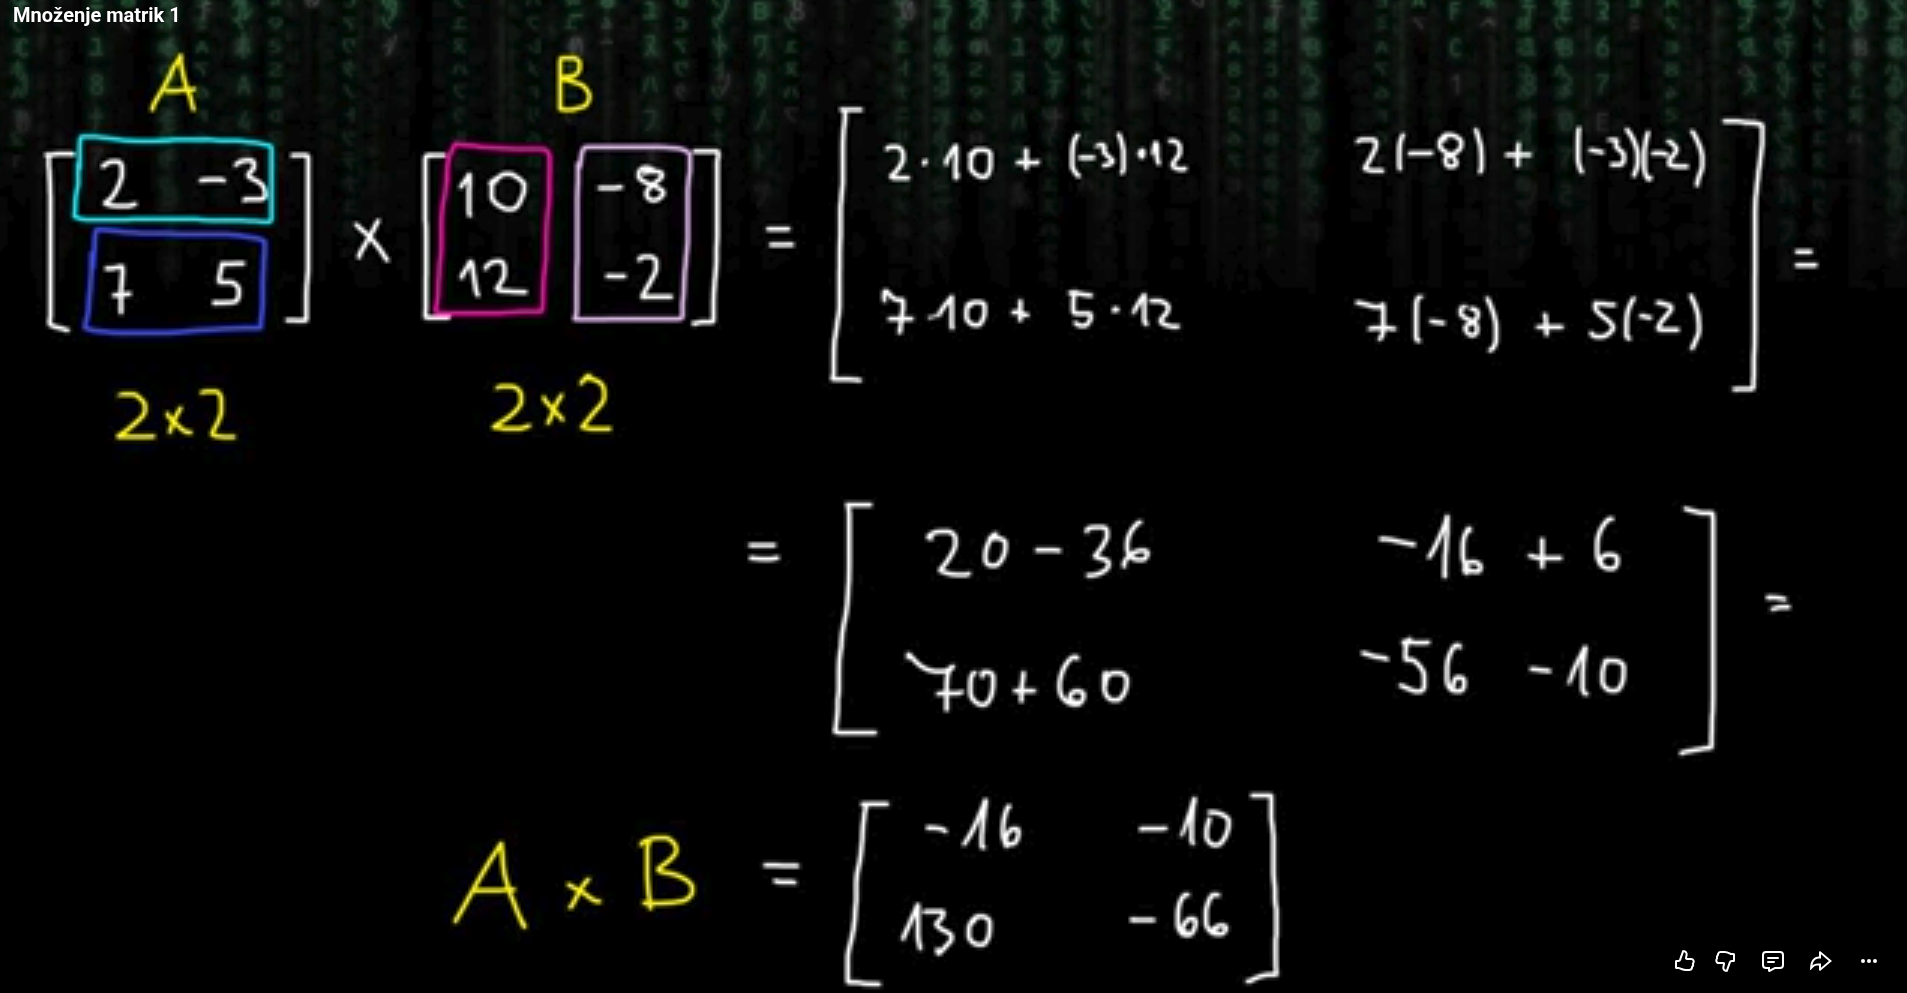 (vir 3)

Pri tem množenju se mora ujemati št. stolpcev prve matrice z številom vrdtic druge matrice. 

Dve pravili za množenje matric

1.   Notranje dimenzije matric se morata ujemati
* `(3,2) @ (3,2) ` to ne bi delalo
* `(3,2) @ (2,3) ` to  bi delalo
2.   Matrica, ki je rezultat, ima obliko zunanjih dimenzij
* `(3,2) @ (2,3) ` -> `(3,3)`






In [75]:

a=torch.tensor([[1,2],[3,4]])

b=torch.tensor([[10,20],[30,40]])

c= torch.tensor([[10,20,50],[30,40,60]])

print(f"Množenje z *: \n{(a*b)}")
print()
print(f"Monženje z @: \n{a@b}")
print()
print(f"Monženje z @: \n{a@c}")

Množenje z *: 
tensor([[ 10,  40],
        [ 90, 160]])

Monženje z @: 
tensor([[ 70, 100],
        [150, 220]])

Monženje z @: 
tensor([[ 70, 100, 170],
        [150, 220, 390]])


### Errorji oblik

In [76]:
tensor_A=torch.tensor([[1,2],
                       [3,4],
                       [5,6]])

tensor_B=torch.tensor([[7,10],
                       [8,11],
                       [9,12]])


# tensor_A @ tensor_B

# RuntimeError: mat1 and mat2 shapes cannot be multiplied (3x2 and 3x2)

Da bomo popravili ta error bomo tensor_B transpozirali. To pomeni da bomo zamenjali dimenziji tensorja. 

In [77]:
print(tensor_B.T)

tensor_A @ tensor_B.T # ni errorja

tensor([[ 7,  8,  9],
        [10, 11, 12]])


tensor([[ 27,  30,  33],
        [ 61,  68,  75],
        [ 95, 106, 117]])

### Redukcija in `dim`

Redukcija se uporablja za zmanjševanje elemntov tensorja (mean, sum...).

Z `dim` se določi v katero smer se bo redukcija izvedla.

- `dim=0` : vertikalno (stolpci)

- `dim=1` : horizontalno (vrstice)

In [78]:
vrednosti=torch.tensor([[10,20,50],
                        [30,40,60]], dtype=torch.float32)

print(f"Povprečje stolpcev: \n{vrednosti.mean(dim=0)}") # isto bi delovalo z min(), max(), sum()...
print()
print(f"Povprečje vrstic: \n{vrednosti.mean(dim=1)}")

Povprečje stolpcev: 
tensor([20., 30., 55.])

Povprečje vrstic: 
tensor([26.6667, 43.3333])


### Izbira podatkov (indeksiranje)

Deluje na podoben način kot pri numpy z indeksiranjem.

`[:]` pomeni vse elemente v eni dimenziji.

In [79]:
x=torch.arange(12).reshape(3,4)

print(x)

print(f"\n{x[0]}") # prva vrstica

print(f"\n{x[1][2]}") # druga vrstice, tretji elemnt

print(f"\n{x[:,1]}") # drugi stolpec

print(f"\nStolpec 3: \n{x[:,2]}") # v tem primeru : pomeni vse vrstice

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

tensor([0, 1, 2, 3])

6

tensor([1, 5, 9])

Stolpec 3: 
tensor([ 2,  6, 10])


### Argmax in argmin

Uporablja se za iskanje največjih vresnosti. 

In [80]:
print(f"Indeks največje vrednosti v tensorju: {torch.argmax(x)}")
print(f"\nIndeks največje vrednosti v vrsticah: {torch.argmax(x,dim=1)}")

Indeks največje vrednosti v tensorju: 11

Indeks največje vrednosti v vrsticah: tensor([3, 3, 3])


### Reshaping, stacking, squeezing in unsqueezing tensorjev

* Reshaping: preoblikuje tensor v določen shape.
* View:  podobno kot resahping, samo da se memory ohrani. Sprememba drugega tensorja spremeni prvi tensor. 
* Stacking: združi več tensorjev drug na drugega (vstack) oz. drug zdraven drugega (hstack).
* Squeez: odstrani vse `1` dimenzije iz tensorja.
* Unsqueez: doda `1` dimenzije v tensor.
* Permute: vrne view inputa z permutiranimi dimenzijami.

In [81]:
z = torch.arange(1. ,11.)
z, z.shape

(tensor([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]), torch.Size([10]))

In [82]:
# RESHAPE

# z_reshape= z.reshape(1,7)

# RuntimeError: shape '[1, 7]' is invalid for input of size 9

# Oblika mora biti kompatibilna s številom elementov

z_reshape= z.reshape(2,5)

z_reshape,z_reshape.shape

(tensor([[ 1.,  2.,  3.,  4.,  5.],
         [ 6.,  7.,  8.,  9., 10.]]),
 torch.Size([2, 5]))

In [83]:
# STACKED

z_stacked= torch.stack([z,z,z], dim=0)
z_stacked

tensor([[ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.],
        [ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.],
        [ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10.]])

In [84]:
# Squeez in unsqueez

z_unsqueez = torch.unsqueeze(z, dim=0) # doda 1 dimenzijo

z_squeez = torch.squeeze(z_unsqueez)

z.shape,z_unsqueez.shape,z_squeez.shape

(torch.Size([10]), torch.Size([1, 10]), torch.Size([10]))

In [85]:
# Permute

z_permute = torch.permute(z_reshape, dims=(1,0))

z_reshape, z_permute,

(tensor([[ 1.,  2.,  3.,  4.,  5.],
         [ 6.,  7.,  8.,  9., 10.]]),
 tensor([[ 1.,  6.],
         [ 2.,  7.],
         [ 3.,  8.],
         [ 4.,  9.],
         [ 5., 10.]]))

### torch.gather()

Za iskanje določenih elementov.

In [86]:
podatki=torch.rand_like(x,dtype=torch.float32)
elementi_za_izbor=torch.tensor([[2],[0],[3]]) #indeksi željenih vrednosti

željene_vrednosti=torch.gather(podatki,dim=1, index=elementi_za_izbor) #dim=1 za horizontalen izbor (po vrsticah)

print(podatki)
print()
print(željene_vrednosti) #rezultat so izbrane vrednosti v vsaki vrstici



tensor([[0.4452, 0.1258, 0.9554, 0.1330],
        [0.7672, 0.6757, 0.6625, 0.2297],
        [0.9545, 0.6099, 0.5643, 0.0594]])

tensor([[0.9554],
        [0.7672],
        [0.0594]])


### PyTorch in NumPy

- Podatki v numpy -> PyTorch tensor : `torch.from_numpy(ndarray)`
- PyTorch tensor -> NumPy array : `torch.Tensor.numpy()`


In [87]:
# Iz arraya v tensor

array = np.arange(1.0, 8.0)
tensor_iz_array = torch.from_numpy(array) # trba pazit na dtype (se ohrani): numpy float64, torch float32

array, tensor_iz_array

(array([1., 2., 3., 4., 5., 6., 7.]),
 tensor([1., 2., 3., 4., 5., 6., 7.], dtype=torch.float64))

In [88]:
# Iz tensorja v array

tensor = torch.ones(10,2)
numpy_tensor = tensor.numpy() # spet se ohrani originalni dtype

tensor,numpy_tensor

(tensor([[1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.],
         [1., 1.]]),
 array([[1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.],
        [1., 1.]], dtype=float32))

## Ponovljivost

Da bomo zmanjšali naključnost v nevronskih mrežah bomo uporabili koncept naključngega semena (**random seed**)

In [89]:
naključni_tensor_A = torch.rand(2,5)

naključni_tensor_B = torch.rand(2,5)

print(f"{naključni_tensor_A}\n{naključni_tensor_B}")

print(naključni_tensor_A == naključni_tensor_B)

tensor([[0.7099, 0.4250, 0.2709, 0.9295, 0.6115],
        [0.2234, 0.2469, 0.4761, 0.7792, 0.3722]])
tensor([[0.2147, 0.3288, 0.1265, 0.6783, 0.8870],
        [0.0293, 0.6161, 0.7583, 0.5907, 0.3219]])
tensor([[False, False, False, False, False],
        [False, False, False, False, False]])


In [90]:
# Nastavimo naključno seme

RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)

naključni_tensor_C = torch.rand(2,5)

torch.manual_seed(RANDOM_SEED)  # Nastaviti ga je potrebno vsakič ko uporabimo naključnost

naključni_tensor_D = torch.rand(2,5)

print(f"{naključni_tensor_C}\n{naključni_tensor_D}")

print(naključni_tensor_C == naključni_tensor_D)



tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936, 0.9408, 0.1332]])
tensor([[0.8823, 0.9150, 0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936, 0.9408, 0.1332]])
tensor([[True, True, True, True, True],
        [True, True, True, True, True]])


### Delovanje tensorjev na GPU

Za lokalno delovanje je potrebno naložiti CUDA driverje. 

https://pytorch.org/get-started/locally/

In [91]:
# Ali lahko uporabimo GPU


torch.cuda.is_available()        # True če CUDA deluje
#torch.cuda.device_count()        # število GPU
#torch.cuda.get_device_name(0)    # npr. "NVIDIA GeForce RTX 3050"
#torch.version.cuda               # CUDA version 


False

### Koda za agnosticiranje naprave



In [92]:
# Če je na voljo GPU uporabi CUDA, drugače CPU

device = "cuda" if torch.cuda.is_available() else "cpu"

device

'cpu'

#### Premik tensorjev in modelov na GPU

`.to(device)`

Transformiranje v numpy array ne bo deloval, če je device = "cuda", saj deluje samo na CPU. Če tensor želimo dati nazaj na cpu uporabimo `.cpu()`

In [93]:
tensor=tensor.to(device)
tensor.device

device(type='cpu')

## PYTorch Workflow

1. Priprava podatkov
2. Grajenje modela
3. Treniranje modela
4. Predikcije in evaluiranje modela
5. Shranjevanje in nalaganje modela
6. Celoten workflow

In [94]:
from torch import nn # vsebuje vse graditelje za nevronsko mrežo
import matplotlib.pyplot as plt

### Podatki (priprava in nalaganje)

Podatki so lahko kar koli(tabele, slike, video, audio, tekst...).

Strojno učenje se v osnovi deli na:

1. Pretvarjanje podatkov v številke

2. Grajenje modela, da se uči vzorcev v številkah

Ustvarili bomo podatke z linearno regresijo.

Naredili bomo ravno linijo s parametri z uporabo formule za linearno regresijo `Y=kX+n`

In [95]:
tensor= torch.rand(2,3)
tensor

tensor([[0.9346, 0.5936, 0.8694],
        [0.5677, 0.7411, 0.4294]])

In [96]:
# Naredimo parametre

utež= 0.7
bias = 0.3

#dodatni podatki
start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1) # input

print(X.shape)
y = utež * X + bias # output

print(X[:10])
print(y[:10])



torch.Size([50, 1])
tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])
tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
        [0.3700],
        [0.3840],
        [0.3980],
        [0.4120],
        [0.4260]])


### Deljenje podatkov na učne in testne sete

- učni podatki 60-80%
- validacijski podatki (za ponovno prilagajanje parametrov) 10-20% (ni vedno potreben)
- testni podatki (za testiranje generalizacije modela) 10-20%

In [97]:
# Naredimo set za učenje

učni_podatki = int(0.8 * len(X)) # da dobimo  število podatkov (80%) iz celotnega dataseta

X_učni_podatki, y_učni_podatki = X[:učni_podatki], y[:učni_podatki] # prvih 80% vrednosti (40 vrednosti od celote 50)

X_testni_podatki, y_testni_podatki = X[učni_podatki:], y[učni_podatki:] # ostalih 20 % (torej od 40 vrednosti naprej)

len(X_učni_podatki), len(X_testni_podatki)

(40, 10)

#### Vizualiziranje podatkov 

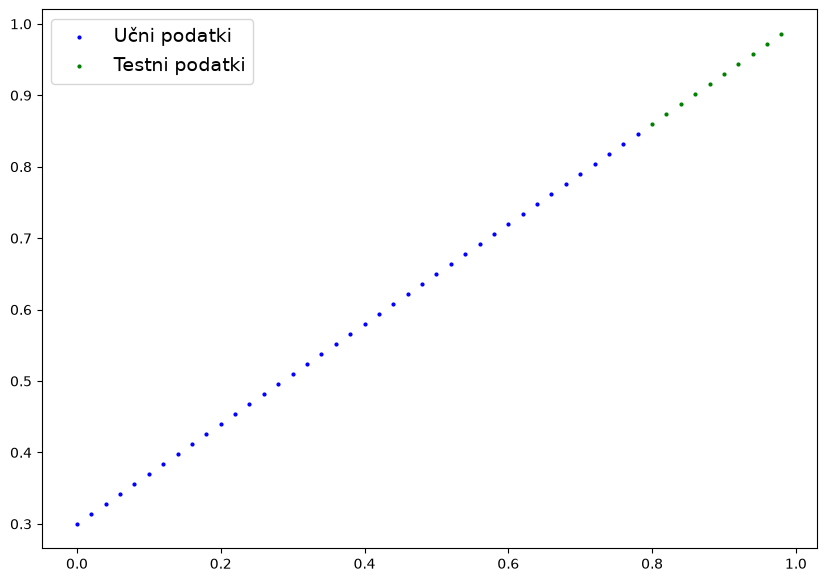

In [98]:
def izris_napovedi(train_data=X_učni_podatki,
                   train_labels=y_učni_podatki,
                   test_data=X_testni_podatki,
                   test_labels=y_testni_podatki,
                   napoved=None):

    """
    Izriše podatke za učenje, testne podatke, ter primerja napovedi
    """

    plt.figure(figsize=(10,7))

    # Izris podatkov za učenje v modrem

    plt.scatter(train_data, train_labels, c="b", s=4, label="Učni podatki")

    # Izris podatkov za testiranje v zelenem

    plt.scatter(test_data, test_labels, c="green", s=4, label= "Testni podatki")

    if napoved is not None:
        plt.scatter(test_data, napoved, c="r", s=4, label="Napoved")

    # legenda

    plt.legend(prop={"size":14})


izris_napovedi()

## Grajenje modela

### Forward pass
 
Forward pass je v bistvu modelov prvi ugib.

Model temelji na tej formuli: 

`ŷ=XW + b` kjer je X vnos, W utež, b pa bias. ŷ pa je modelova napoved oz. ugib.

Torej ko učimo model spreminjamo W in b.

In [99]:
#Podaki, ki sledijo liniji y=2x+1

N = 10 # naši podatki imajo 10 datapointov


# vsak data point ima en input feature in 1 output value

D_in=1 
D_out=1

#Input podatki

X=torch.randn(N, D_in)

print(X)
print()

# Naredimo pravilne target lable y z pravim W in pravim b
#Pravi W je 2.0 in pravi b je 1

praviln_W=torch.tensor([[2.0]])

praviln_b = torch.tensor(1.0)

# resnica
praviln_Y= X @ praviln_W +praviln_b +torch.randn(N, D_out) * 0.1  # 0.1 je za noise

print(praviln_Y)
print()

# Nraedimo začetne uteži in bias
W = torch.randn(D_in, D_out, requires_grad=True)
b = torch.randn(1, requires_grad=True)

print(f"Začetne uteži W: \n{W}\n")  # To je modelov prvotni ugib, ki je popolnoma napačen
print(f"Začetni bias b: \n{b}")

tensor([[ 0.4617],
        [ 0.2674],
        [ 0.5349],
        [ 0.8094],
        [ 1.1103],
        [-1.6898],
        [-0.9890],
        [ 0.9580],
        [ 1.3221],
        [ 0.8172]])

tensor([[ 1.8467],
        [ 1.4596],
        [ 2.2051],
        [ 2.6873],
        [ 3.1878],
        [-2.3001],
        [-0.9498],
        [ 2.9216],
        [ 3.6965],
        [ 2.6105]])

Začetne uteži W: 
tensor([[-0.0499]], requires_grad=True)

Začetni bias b: 
tensor([0.5263], requires_grad=True)


Formulo y=XW+b uporabimo v kodi:

`y_hat= X @ W +b`

In [100]:

y_hat= X @ W +b

print(f"Predikcija y_hat (prve tri vrstice): \n{y_hat[:3]}\n")
print(f"Pravilni label praviln_y (prve tri vrstice): \n{praviln_Y[:3]}")


Predikcija y_hat (prve tri vrstice): 
tensor([[0.5033],
        [0.5130],
        [0.4996]], grad_fn=<SliceBackward0>)

Pravilni label praviln_y (prve tri vrstice): 
tensor([[1.8467],
        [1.4596],
        [2.2051]])


Rezultati y_hat se niti malo ne ujemajo z resnico (pravilni_Y).

### Backward pass

Ugotoviti kako napačen je bil forward pass ugib. To bomo ugotovili z loss.
Loss bomo ugotovili z mean squared error (MSE).

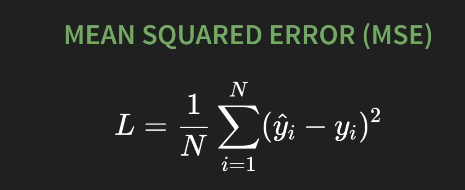

To pomeni, da bomo za vsako napoved:

1. `(y_hat - praviln_Y)`
2. nato bomo dobljeno dali na kvadrat, da dobimo pozitivno številko
3. Na koncu pa bomo izračunali povprečje teh vrednosti

V kodi to pomeni:

In [101]:
napaka=y_hat - praviln_Y
napaka_na_kvadrat= napaka ** 2

loss=napaka_na_kvadrat.mean()

print(f"Loss: {loss}")

Loss: 4.959339141845703


Zdaja rabimo ugotoviti za koliko spremeniti W in b da zmanjšamo loss. To bomo naredili z autogradom in sicer gradient lossa v odnosu do W (uteži) in gradient lossa v odnosu do b (biasa).

To bomo naredili z `loss.backward()` (tu pridejo v poštev vse vrednosti, ki imajo`requires_grad=True`)

In [102]:
loss.backward()

print(f"Gradient za W: \n{W.grad}\n")
print(f"Gradient za b: \n{b.grad}\n")

Gradient za W: 
tensor([[-4.2733]])

Gradient za b: 
tensor([-2.4564])



Negativen `.W.grad` pomeni pomeni, da če bomo povečali W, se bo loss zmanjšal

`.grad()` nam pove za koliko rabimo spremeniti W in b.

To ponovimo, dokler nismo zadovoljni z rezultatom. Temu se reče  **training loop** pri katerem se upošteva **gradient descent** .

### Algoritem gradient descent

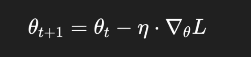

- Θ predstavlja vse parametre. V našem primeru W in b.

- η stopnja učenja. Ponavadi majhna številja (0.01), kki določa, kako velik korak naredimo pri vsaki posodobitvi parametrov.

- {\displaystyle \nabla } *L* predstavlja gradient lossa. Kar smo izračunali v prejšnem koraku (W.grad in b.grad)

v kodi to pomeni:

`nov_W = star_W - learning_rate * W.grad`

`nov_b = star_b - learning_rate * b.grad`

To ponavljamo čez več epoh. Ena epoha je en training loop.

### Training loop

Pomembni sta dve funkciji:

- `torch.no_grad()` ki sporoča torchu, da naj ne spremlja sprememb parametrov, saj jih bomo spreminjali ročno

- `.grad.zero_()` ki sporoča, da je potrebno resetirat gradiente po vsaki epohi. 

In [103]:
#hiperparametri

learning_rate, epohe= 0.01, 1000

#ponovno definiramo parametre (začeten ugib)
W, b =torch.randn(1,1, requires_grad=True), torch.randn(1, requires_grad=True)

#Training loop

for epoha in range(epohe):

    #forwardpass in loss
    y_hat = X @ W + b
    loss = torch.mean((y_hat-praviln_Y)**2)

    # backward pass
    loss.backward()

    #Update parametrov
    with torch.no_grad():
        W-=learning_rate * W.grad; b -= learning_rate * b.grad

    #resetiramo gradiente
    W.grad.zero_(); b.grad.zero_()


    # prikaz učenja modela
    if epoha % 10 == 0:
        print(f"Epoha {epoha:02d}: Loss={loss.item():.4f}, W={W.item():.3f}, b={b.item():.3f}")


print(f"\nFinalni paramteri: W={W.item():.3f}, b={b.item():.3f}") 

print("Pravi parametri W=2.000, b=1.000")

Epoha 00: Loss=4.3332, W=0.032, b=0.749
Epoha 10: Loss=2.7072, W=0.389, b=0.916
Epoha 20: Loss=1.7214, W=0.674, b=1.032
Epoha 30: Loss=1.1165, W=0.903, b=1.109
Epoha 40: Loss=0.7398, W=1.086, b=1.158
Epoha 50: Loss=0.5013, W=1.235, b=1.188
Epoha 60: Loss=0.3474, W=1.356, b=1.203
Epoha 70: Loss=0.2459, W=1.455, b=1.208
Epoha 80: Loss=0.1777, W=1.536, b=1.206
Epoha 90: Loss=0.1307, W=1.603, b=1.200
Epoha 100: Loss=0.0977, W=1.659, b=1.191
Epoha 110: Loss=0.0741, W=1.706, b=1.180
Epoha 120: Loss=0.0570, W=1.745, b=1.168
Epoha 130: Loss=0.0443, W=1.778, b=1.156
Epoha 140: Loss=0.0349, W=1.806, b=1.144
Epoha 150: Loss=0.0278, W=1.830, b=1.133
Epoha 160: Loss=0.0223, W=1.850, b=1.122
Epoha 170: Loss=0.0182, W=1.867, b=1.112
Epoha 180: Loss=0.0150, W=1.882, b=1.103
Epoha 190: Loss=0.0126, W=1.895, b=1.094
Epoha 200: Loss=0.0107, W=1.907, b=1.086
Epoha 210: Loss=0.0092, W=1.916, b=1.079
Epoha 220: Loss=0.0081, W=1.925, b=1.073
Epoha 230: Loss=0.0072, W=1.932, b=1.067
Epoha 240: Loss=0.0065, W=

Loss se je zmanjševal W in b pa sta postajala čedalje bližje pravima W in b.

## Modul torch.nn

Modul za gradnjo nevronskih mrež. Vsebuje vse gradnike, ki so potrebovane: plasti, aktivacijske funkcije, funkcije izgube in osnovni razred za svoje modele.

Najpomembnejša funkcija je:

- `torch.nn.Linear`: je zakar smo v prešnjem modelu uporabljali `X @ W + b`. Zapakira W in b v objekt.


In [104]:
# Input ima en feature, output pa eno vrednost

D_in=1
D_out=1

# Naredimo linarni sloj

linear_layer = torch.nn.Linear(in_features=D_in, out_features=D_out)

print(f"Linerne uteži (W): {linear_layer.weight}\n")

print(f"Linerne bias (b): {linear_layer.bias}\n")

# Uporablja se kot funkcijo. To je forward pass (prvi ugib)
# X je tensor [10, 1] iz prejšnjega poglavja

y_hat_nn = linear_layer(X)

print(f"Output nn.Liner (prve tri vrstice); \n{y_hat_nn[:3]}")

Linerne uteži (W): Parameter containing:
tensor([[0.3064]], requires_grad=True)

Linerne bias (b): Parameter containing:
tensor([-0.2083], requires_grad=True)

Output nn.Liner (prve tri vrstice); 
tensor([[-0.0669],
        [-0.1264],
        [-0.0444]], grad_fn=<SliceBackward0>)


Lahko vidimo da funkcija sama naredi uteži in bias ter da `requires_grad=True`

Torej **Parameter** je tensor, ki ima:
- `requires_grad=True`
- se sam naredi ob stavritvi modela
- sledi spremembam

Imajo pa slabost, da lahko prepoznajo samo premico. Torej ne delujejo z zahtevnimi inputi. 

Zato potrebujemo **aktivacijsko funkcijo**, ki vnese v mrežo nelinaernost.

### `nn.ReLu`

Rectefied linear unit. Deluje po principu, če je input negativen, ga naredi 0. 

In [105]:
relu = torch.nn.ReLU()
testni_podatki = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])

aktivirani_podatki = relu(testni_podatki)

print(f"Originalni podatki: {testni_podatki}")
print(f"Aktivirani podatki: {aktivirani_podatki}")

Originalni podatki: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
Aktivirani podatki: tensor([0.0000, 0.0000, 0.0000, 0.5000, 2.0000])


### `nn.GELU`

Gaussian error linear unit. Gladkejša verzija ReLu. Se uporablja v modernih transformerjih.

In [106]:
gelu = torch.nn.GELU()

testni_podatki = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])

aktivirani_podatki = gelu(testni_podatki)

print(f"Originalni podatki: {testni_podatki}")
print(f"Aktivirani podatki: {aktivirani_podatki}")


Originalni podatki: tensor([-2.0000, -0.5000,  0.0000,  0.5000,  2.0000])
Aktivirani podatki: tensor([-0.0455, -0.1543,  0.0000,  0.3457,  1.9545])


### `nn.Softmax`

Uporablja se za zadnjo plast pri klasifikaciji. Konverta surove napovedi modela (logits) v distribucijo verjetnosti. Vrednosti bodo med 0 in 1, ter njihova vsota bo 1.

In [107]:
softmax= torch.nn.Softmax(dim=1)

# surove napovedi modelov za dva predmeta, čez 4 možne razrede

logits= torch.tensor([[1.0, 3.0, 0.5, 1.5], [-1.0, 2.0, 1.0, 0.0]])

verjetnosti=softmax(logits)

print(f"Verjetnosti outputa: \n{verjetnosti}\n")
print(f"Vsota verjetnosti za prvi predmet: {verjetnosti[0].sum()}")

Verjetnosti outputa: 
tensor([[0.0939, 0.6942, 0.0570, 0.1549],
        [0.0321, 0.6439, 0.2369, 0.0871]])

Vsota verjetnosti za prvi predmet: 1.0


### `nn.Embedding`

Spremeni besede v številke. Vsaka beseda dobi svoj unikaten vektor.
 

In [108]:
vocab_size = 10 # Naš jezik ima 10 unikatnih besed
embedding_dim = 3 # Vsaka beseda bo predstavljena kot 3D vector


# Naredi matrico uteži določene oblike, z naključnimi številkami 
embedding_layer = torch.nn.Embedding(vocab_size, embedding_dim) 

# input je stavek, kjer je vsaka beseda ID. Npr. 1, 5, 0, 8

input_ids = torch.tensor([[1, 5, 0, 8]])

besedni_vektorji= embedding_layer(input_ids)

print(f"Input token (oblike [1,4]): \n{input_ids}\n")
print(f"Izhodni vektroji besed (oblike [1,4,3]): \n{besedni_vektorji}")

Input token (oblike [1,4]): 
tensor([[1, 5, 0, 8]])

Izhodni vektroji besed (oblike [1,4,3]): 
tensor([[[-0.1973, -1.0546,  1.2780],
         [ 0.4880,  0.7846,  0.0286],
         [ 2.2181,  0.5232,  0.3466],
         [ 0.4048,  0.1785,  0.2649]]], grad_fn=<EmbeddingBackward0>)


### `nn.Layernorm`

Preprečuje izginotje vrednosti, saj jih preračuna v stabilen obsag. Na nek način normalizira vrednosti v tensorju

In [109]:
# Besedni vektorji imajo dimenzijo 3

norm_layer = torch.nn.LayerNorm(normalized_shape=3)
input_features = torch.tensor([[[1.0, 2.0, 3.0],[4.0, 5.0, 6.0]]])
normalizirani_featurji = norm_layer(input_features)

print(f"input_features: \n{input_features}\n")
print(f"normalizirani_featurji: \n{normalizirani_featurji}\n")
print(f"Povprečje (moralo bi biti okoli 0): \n{normalizirani_featurji.mean(dim=-1)}")

input_features: 
tensor([[[1., 2., 3.],
         [4., 5., 6.]]])

normalizirani_featurji: 
tensor([[[-1.2247,  0.0000,  1.2247],
         [-1.2247,  0.0000,  1.2247]]], grad_fn=<NativeLayerNormBackward0>)

Povprečje (moralo bi biti okoli 0): 
tensor([[0., 0.]], grad_fn=<MeanBackward1>)


### `nn.Dropout`

Preprečuje prenaučenost modela, s tam da naključno spremeni nekatere nevrona na 0, ter s tam zmanjša zanašanje modela na posamezne nevrone. Dekuje samo med učenjem.


In [110]:
dropout_layer = torch.nn.Dropout(p=0.5)
input_tensor = torch.ones(1, 10)

# Aktivacija dropouta za učenje
dropout_layer.train()
output_med_učenjem = dropout_layer(input_tensor)

# deaktiviramo dropout za evaluacijo 
dropout_layer.eval()
output_med_evaluacijo = dropout_layer(input_tensor)

print(f"Input: \n{input_tensor}\n")
print(f"Output med učenjem (naključne vrednosti spremenjene v 0 ostale pa skalirane): \n{output_med_učenjem}\n")
print(f"Output med evaluacijo (brez spremembe): \n{output_med_evaluacijo}\n")


Input: 
tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

Output med učenjem (naključne vrednosti spremenjene v 0 ostale pa skalirane): 
tensor([[2., 2., 0., 2., 2., 0., 2., 0., 2., 2.]])

Output med evaluacijo (brez spremembe): 
tensor([[1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])



## `nn.Module` in `torch.optim`

### `nn.Module`

Je osnovni razred za vse nevronske mreže in njihove dele (plasti, bloke, cele modele). Naredi tri stvari:
 
- Hrani parametre. Vse, kar je nn.Parameter (uteži, pristranskosti), se samodejno registrira in je dostopno prek model.parameters().

- Definira računanje v metodi forward(). Model pokličeš kot funkcijo (model(x)), PyTorch pa v ozadju pokliče forward.

- Gnezdi se. Modul lahko vsebuje druge module, kar omogoča sestavljanje zapletenih arhitektur iz preprostih blokov.

Poleg tega skrbi za state_dict() (shranjevanje/nalaganje uteži), .to(device) (premik na GPU), .train() / .eval() (preklop načina za dropout, batchnorm).

### `torch.optim`

Ta modul vsebuje optimizatorje (SGD, Adam, AdamW, RMSprop ...). Optimizator ne ve nič o arhitekturi: dobi seznam parametrov in njihove gradiente ter jih po določenem pravilu posodobi.



## Ponovno grajenje modela

In [111]:
import torch.nn as nn


# podedujemo od nn,Module

class LinearRegressionModel(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()

        # v konstruktortju definiramo plasti, ki jih bomo uporabili
        self.linear_layer= nn.Linear(in_features, out_features)

    def forward(self, x):
        # V forward pasuu (prvi ugib) povežemo plasti
        return self.linear_layer(x)


# ustvarimo model

model= LinearRegressionModel(in_features=1, out_features=1)

print("Arhitektura modela: ")
print(model)




Arhitektura modela: 
LinearRegressionModel(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)


In [112]:
import torch.optim as optim 

# hiperparametri 
learning_rate = 0.1

# NAredimo Adam optimizator.
# Nato mu damo model.paramteres(), da mu povemo katere tensorje naj upravlja

optimizer= optim.Adam(model.parameters(), lr=learning_rate)

# dodamo še v naprej narejeno funkcijo za loss

loss_fn = nn.MSELoss() # Povprečena kvadratna napaka za loss

### Training loop: 

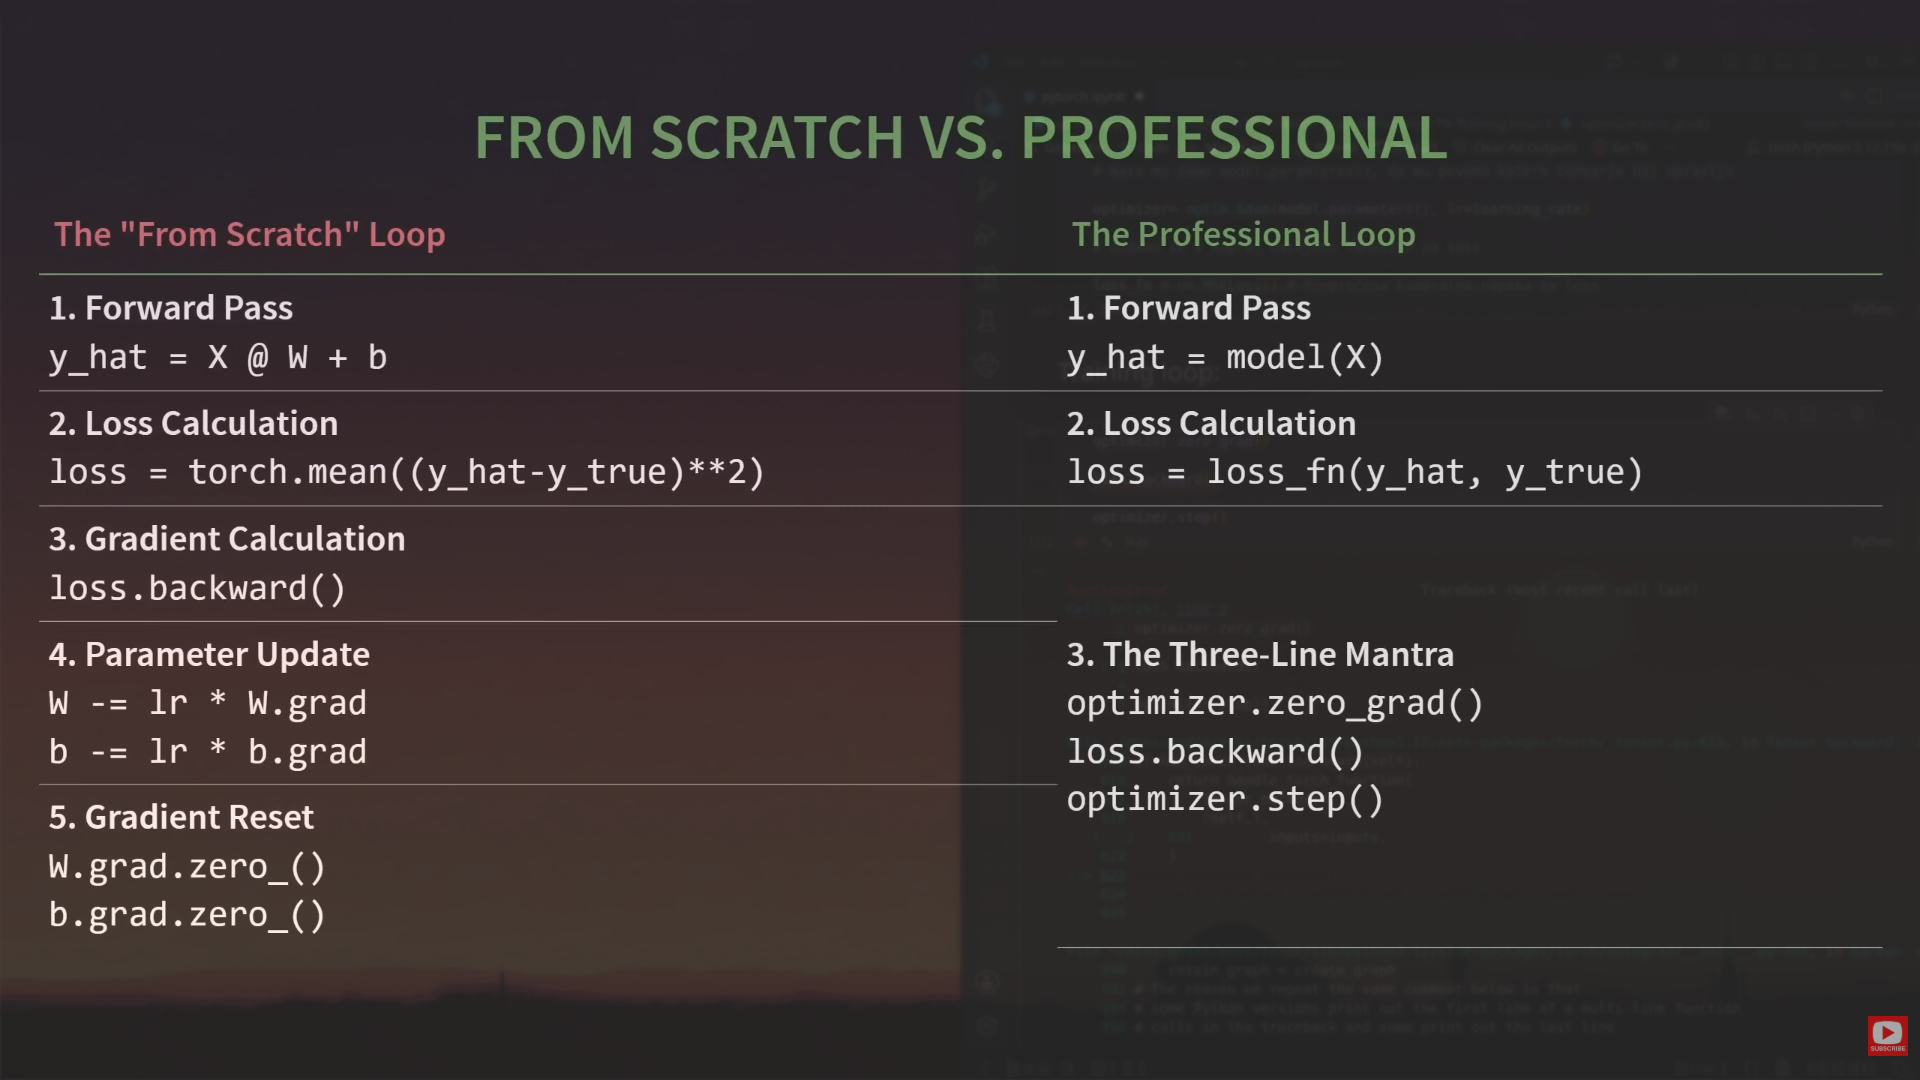

In [113]:

epohe= 100

for epoha in range(epohe):

    # FORWARD PASS
    y_hat=model(X)

    # Izračun lossa

    loss= loss_fn(y_hat, praviln_Y)

    # izničit gradiente
    optimizer.zero_grad()

    # Izračun gradientov
    loss.backward()

    # Posodobitev parametrov
    optimizer.step()


    # Napredek
    if epoha % 10 == 0:
        print(f"Epoha {epoha: 02d}: Loss={loss.item():.4f}")



Epoha  0: Loss=8.5013
Epoha  10: Loss=2.8702
Epoha  20: Loss=1.1374
Epoha  30: Loss=0.2514
Epoha  40: Loss=0.0124
Epoha  50: Loss=0.0243
Epoha  60: Loss=0.0197
Epoha  70: Loss=0.0107
Epoha  80: Loss=0.0045
Epoha  90: Loss=0.0044


viri:

0. https://docs.pytorch.org/docs/2.14/index.html
1. https://www.youtube.com/watch?v=r1bquDz5GGA&t=329s
2. https://www.youtube.com/watch?v=V_xro1bcAuA&t=2640s
3. https://www.youtube.com/watch?v=woSNI-aejnU